<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Experiment 23: Bayesian Network Construction and Visualization

This notebook builds a decision-support medical diagnosis network to reason about patient symptoms under uncertainty.
We will construct a Bayesian Network containing the following nodes:
*   **Smoking** ($S$)
*   **Pollution** ($P$)
*   **Lung Disease** ($L$)
*   **Cough** ($C$)
*   **X-ray Result** ($X$)
*   **Fatigue** ($F$)

We define a realistic medical structure where:
*   *Smoking* and *Pollution* are causes of *Lung Disease*.
*   *Lung Disease* leads to symptoms: *Cough*, *X-ray Result*, and *Fatigue*.
```

```markdown
## Step 0: Install and Import Necessary Libraries
```

In [4]:
!pip install -q pgmpy networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.independencies import Independencies

```markdown
## Step 1: Define the Directed Acyclic Graph (DAG) in pgmpy
We construct the model structure by defining the directed edges between variables.
```

In [5]:
# Define the network structure using DiscreteBayesianNetwork
model = DiscreteBayesianNetwork([
    ('Smoking', 'Lung Disease'),
    ('Pollution', 'Lung Disease'),
    ('Lung Disease', 'Cough'),
    ('Lung Disease', 'X-ray Result'),
    ('Lung Disease', 'Fatigue')
])

print("Nodes in the model:", model.nodes())
print("Edges in the model:", model.edges())

Nodes in the model: ['Smoking', 'Lung Disease', 'Pollution', 'Cough', 'X-ray Result', 'Fatigue']
Edges in the model: [('Smoking', 'Lung Disease'), ('Lung Disease', 'Cough'), ('Lung Disease', 'X-ray Result'), ('Lung Disease', 'Fatigue'), ('Pollution', 'Lung Disease')]


```markdown
## Step 2: Specify the Conditional Probability Distributions (CPDs)
We specify state names and assign CPD matrices. All variables are modeled as binary (0 = False, 1 = True).
```

In [6]:
# 1. CPD for Smoking (independent node)
cpd_smoking = TabularCPD(variable='Smoking', variable_card=2, values=[[0.7], [0.3]],
                         state_names={'Smoking': [0, 1]})

# 2. CPD for Pollution (independent node)
cpd_pollution = TabularCPD(variable='Pollution', variable_card=2, values=[[0.6], [0.4]],
                           state_names={'Pollution': [0, 1]})

# 3. CPD for Lung Disease (dependent on Smoking and Pollution)
# Evidence order: [Smoking, Pollution]
cpd_lung_disease = TabularCPD(
    variable='Lung Disease', variable_card=2,
    values=[[0.95, 0.80, 0.70, 0.15],
            [0.05, 0.20, 0.30, 0.85]],
    evidence=['Smoking', 'Pollution'],
    evidence_card=[2, 2],
    state_names={
        'Lung Disease': [0, 1],
        'Smoking': [0, 1],
        'Pollution': [0, 1]
    }
)

# 4. CPD for Cough (dependent on Lung Disease)
cpd_cough = TabularCPD(variable='Cough', variable_card=2,
                       values=[[0.90, 0.25],
                               [0.10, 0.75]],
                       evidence=['Lung Disease'], evidence_card=[2],
                       state_names={'Cough': [0, 1], 'Lung Disease': [0, 1]})

# 5. CPD for X-ray Result (dependent on Lung Disease)
cpd_xray = TabularCPD(variable='X-ray Result', variable_card=2,
                      values=[[0.98, 0.15],
                              [0.02, 0.85]],
                      evidence=['Lung Disease'], evidence_card=[2],
                      state_names={'X-ray Result': [0, 1], 'Lung Disease': [0, 1]})

# 6. CPD for Fatigue (dependent on Lung Disease)
cpd_fatigue = TabularCPD(variable='Fatigue', variable_card=2,
                         values=[[0.85, 0.30],
                                 [0.15, 0.70]],
                         evidence=['Lung Disease'], evidence_card=[2],
                         state_names={'Fatigue': [0, 1], 'Lung Disease': [0, 1]})

# Add CPDs to the model
model.add_cpds(cpd_smoking, cpd_pollution, cpd_lung_disease, cpd_cough, cpd_xray, cpd_fatigue)

```markdown
## Step 3: Validate the Model
We verify that the structure and CPD dimensions match, and that probabilities sum to 1.
```

In [7]:
is_valid = model.check_model()
print(f"Is the model valid? {is_valid}")

Is the model valid? True


```markdown
## Step 4: Draw the Network
We use NetworkX and Matplotlib to visualize the structure of our Bayesian Network.
```

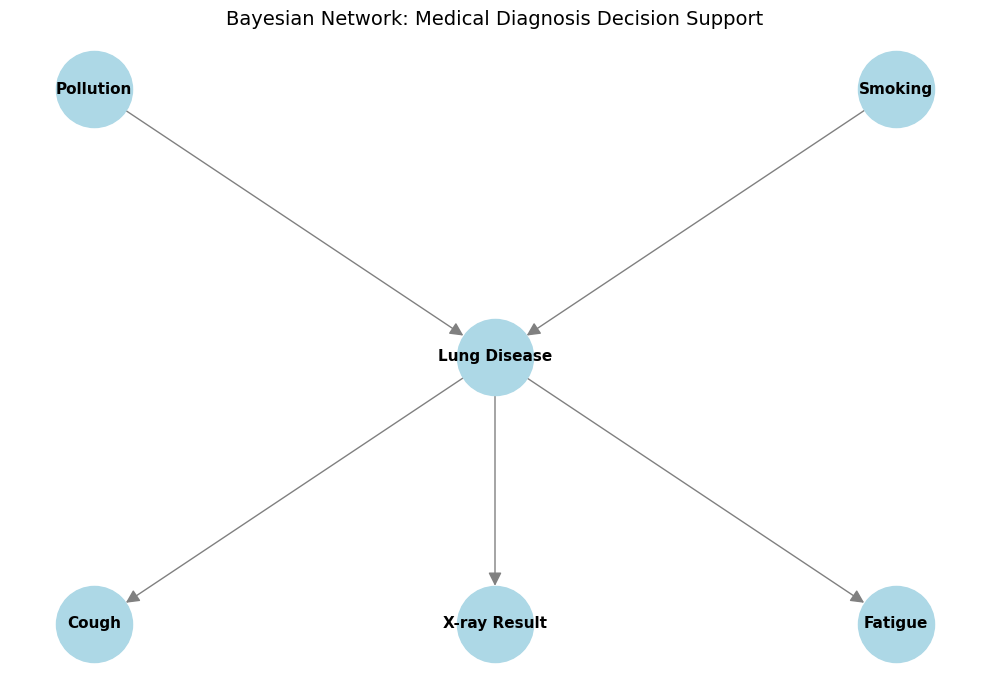

In [8]:
plt.figure(figsize=(10, 7))
pos = {
    'Pollution': (1, 3),
    'Smoking': (3, 3),
    'Lung Disease': (2, 2),
    'Cough': (1, 1),
    'X-ray Result': (2, 1),
    'Fatigue': (3, 1)
}

nx.draw_networkx(
    model,
    pos=pos,
    with_labels=True,
    node_size=3000,
    node_color='lightblue',
    font_size=11,
    font_weight='bold',
    arrowsize=20,
    edge_color='gray'
)
plt.title("Bayesian Network: Medical Diagnosis Decision Support", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

```markdown
## Step 5: Conditional Independencies and Active Trails
We extract conditional independence assertions and look at the information flow (active trails) in the network.
```

In [11]:
print("=== Local Independencies ===")
for node in model.nodes():
    print(f"{node}: {model.local_independencies(node)}")

print("\n=== Examples of Active Trails ===")
# Active trail (d-connection) between Pollution and Smoking when Lung Disease is observed
active_observed = model.is_dconnected('Pollution', 'Smoking', observed=['Lung Disease'])
print(f"Are 'Pollution' and 'Smoking' active when 'Lung Disease' is observed (v-structure)? {active_observed}")

# Active trail (d-connection) between Cough and Fatigue when Lung Disease is NOT observed
active_unobserved = model.is_dconnected('Cough', 'Fatigue')
print(f"Are 'Cough' and 'Fatigue' active when 'Lung Disease' is not observed? {active_unobserved}")

# Active trail (d-connection) between Cough and Fatigue when Lung Disease IS observed
active_blocked = model.is_dconnected('Cough', 'Fatigue', observed=['Lung Disease'])
print(f"Are 'Cough' and 'Fatigue' active when 'Lung Disease' is observed? {active_blocked}")

=== Local Independencies ===
Smoking: (Smoking ⟂ Pollution)
Lung Disease: 
Pollution: (Pollution ⟂ Smoking)
Cough: (Cough ⟂ Fatigue, Pollution, Smoking, X-ray Result | Lung Disease)
X-ray Result: (X-ray Result ⟂ Cough, Fatigue, Pollution, Smoking | Lung Disease)
Fatigue: (Fatigue ⟂ Cough, Pollution, Smoking, X-ray Result | Lung Disease)

=== Examples of Active Trails ===
Are 'Pollution' and 'Smoking' active when 'Lung Disease' is observed (v-structure)? True
Are 'Cough' and 'Fatigue' active when 'Lung Disease' is not observed? True
Are 'Cough' and 'Fatigue' active when 'Lung Disease' is observed? False
